#### Phase 3 - Multi-Task CNN

Loads what `src/train_cnn.py` produced (`models/cnn_gray.h5`, `results/cnn/`). Nothing is retrained here.

A shared convolutional trunk feeds five softmax heads, one per digit. Per-digit and full-sequence accuracy (all five digits right) are reported together.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent / "src"))
from config import CONFIG, resolve_path
from fusion import load_probs
from figures import plot_cnn_ablation


def load_json(key):
    return json.loads(resolve_path(CONFIG["paths"][key]).read_text())


metrics, ablation, history, digit_report = (
    load_json(k) for k in ("cnn_metrics", "cnn_ablation", "cnn_history", "cnn_classification_report"))
model_summary_text = resolve_path(CONFIG["paths"]["cnn_model_summary"]).read_text()

#### 1. Model architecture (`results/cnn/cnn_model_summary.txt`)

Written by `python src/train_cnn.py --report-only` from the saved weights; no retraining.


In [2]:
print(model_summary_text)

Model: "multitask_cnn"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ counter_crop        │ (None, 106, 400,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 106, 400,  │      3,328 │ counter_crop[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 106, 400,  │        512 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_8 (ReLU)      │ (None, 106, 400,  │          

#### 2. Deployed model: validation and test

In [3]:
rows = []
for key, label in [("validation", "validation, +2% crop (deployed)"), ("testing", "test, +2% crop (deployed)"),
                   ("validation_tight_crop", "validation, tight crop"), ("testing_tight_crop", "test, tight crop")]:
    r = metrics[key]
    rows.append({"split / crop": label, "full-sequence": r["full_sequence_accuracy"],
                 "per-digit d1..d5": " / ".join(f"{x:.3f}" for x in r["per_digit_accuracy"])})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\ninput channels: {metrics['input_channels']}, evaluation crop margin: {metrics['eval_crop_margin']:.0%}")

                   split / crop  full-sequence                      per-digit d1..d5
validation, +2% crop (deployed)         0.7975 0.945 / 0.950 / 0.973 / 0.950 / 0.870
      test, +2% crop (deployed)         0.7775 0.941 / 0.951 / 0.954 / 0.956 / 0.879
         validation, tight crop         0.7925 0.945 / 0.953 / 0.980 / 0.960 / 0.865
               test, tight crop         0.7688 0.940 / 0.958 / 0.950 / 0.953 / 0.876

input channels: 1, evaluation crop margin: 2%


#### 3. Per-digit classification report (`results/cnn/cnn_classification_report.json`)

Precision / recall / F1 per digit class, pooled across the five positions (the same pooling
the SVM/RF use). Also written by `--report-only`.


In [4]:
for split in ["validation", "testing"]:
    rep = digit_report[split]
    rows = [{"digit": d, "precision": rep[d]["precision"], "recall": rep[d]["recall"],
             "f1": rep[d]["f1-score"], "support": int(rep[d]["support"])} for d in map(str, range(10))]
    print(f"--- {split} (accuracy = {rep['accuracy']:.4f}) ---")
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    print()


--- validation (accuracy = 0.9375) ---
digit  precision  recall     f1  support
    0     0.9128  0.9682 0.9397      346
    1     0.9770  0.9043 0.9392      282
    2     0.9517  0.9657 0.9586      204
    3     0.9517  0.9381 0.9448      210
    4     0.9325  0.9383 0.9354      162
    5     0.9422  0.9209 0.9314      177
    6     0.9277  0.9222 0.9249      167
    7     0.9071  0.9071 0.9071      140
    8     0.9786  0.9195 0.9481      149
    9     0.8977  0.9693 0.9322      163

--- testing (accuracy = 0.9363) ---
digit  precision  recall     f1  support
    0     0.9164  0.9544 0.9350      724
    1     0.9516  0.9360 0.9437      609
    2     0.9367  0.9601 0.9483      401
    3     0.9231  0.9501 0.9364      341
    4     0.9573  0.9458 0.9515      332
    5     0.9508  0.9325 0.9416      311
    6     0.9159  0.9050 0.9104      337
    7     0.9432  0.9344 0.9388      320
    8     0.9510  0.9122 0.9312      319
    9     0.9324  0.9020 0.9169      306



#### 4. Training-technique ablation

Techniques added one at a time, each keeping the ones before it. Rows 1–5 are seeded RGB
runs at the tight crop; rows 6–7 the deployed grayscale recipe at the +2% crop (`source` column).


              step  val full-sequence                  val per-digit d1..d5  epochs                                                                           source
          baseline             0.1250 0.715 / 0.588 / 0.660 / 0.573 / 0.393      91 RGB input, tight ground-truth crop (seeded run reused from the round-5 ablation)
          +he_init             0.1450 0.770 / 0.635 / 0.733 / 0.642 / 0.458      71 RGB input, tight ground-truth crop (seeded run reused from the round-5 ablation)
           +l2_reg             0.1875 0.780 / 0.693 / 0.777 / 0.667 / 0.475     100 RGB input, tight ground-truth crop (seeded run reused from the round-5 ablation)
    +lr_step_decay             0.1550 0.767 / 0.618 / 0.735 / 0.647 / 0.468     100 RGB input, tight ground-truth crop (seeded run reused from the round-5 ablation)
     +augmentation             0.4525 0.825 / 0.875 / 0.932 / 0.892 / 0.627     264 RGB input, tight ground-truth crop (seeded run reused from the round-5 ablation)
+digit_per

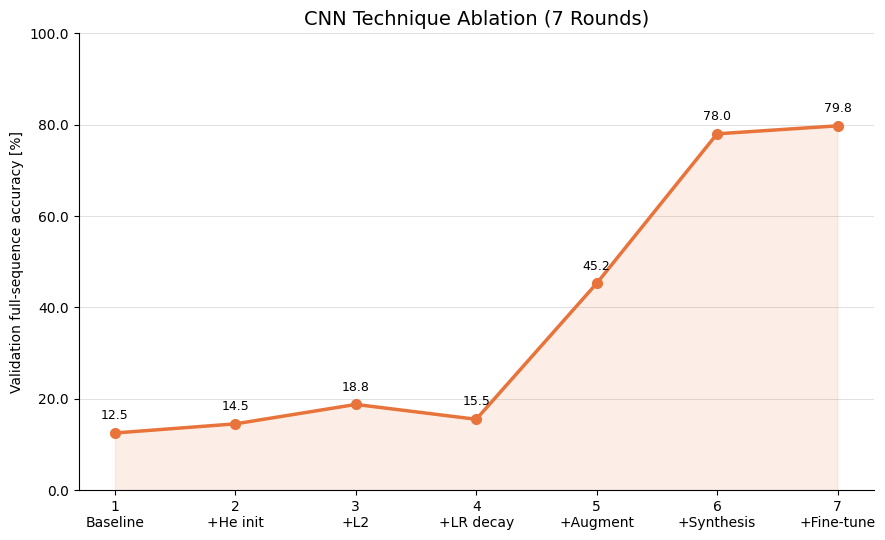

In [5]:
ab = pd.DataFrame([{"step": r["step"], "val full-sequence": r["val_full_sequence_accuracy"],
                    "val per-digit d1..d5": " / ".join(f"{x:.3f}" for x in r["val_per_digit_accuracy"]),
                    "epochs": r.get("epochs_trained"), "source": r.get("source", "")} for r in ablation])
print(ab.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

plot_cnn_ablation()   # src/figures.py; evaluate.py saves the same figure for the Inspector
plt.show()

**Observation:** Initialisation, weight decay and the learning-rate schedule (steps 2–4)
make little difference on 800 training images, which the model can memorise. Augmentation
(step 5) is the first clear gain and
digit-permutation synthesis (step 6) the largest; fine-tuning on real counters (step 7)
adds the last two points.


#### 4a. Grayscale vs. RGB vs. two-CNN combination

Two CNNs are kept: the deployed grayscale model (`models/cnn_gray.h5`) and an earlier RGB model
(`models/cnn_rgb.h5`). Their errors only partly overlap, so the pair is also compared as a simple
combination (`cnn+cnn_rgb` in `results/fusion/fusion_metrics.json`). Full fusion is in `06_fusion.ipynb`.


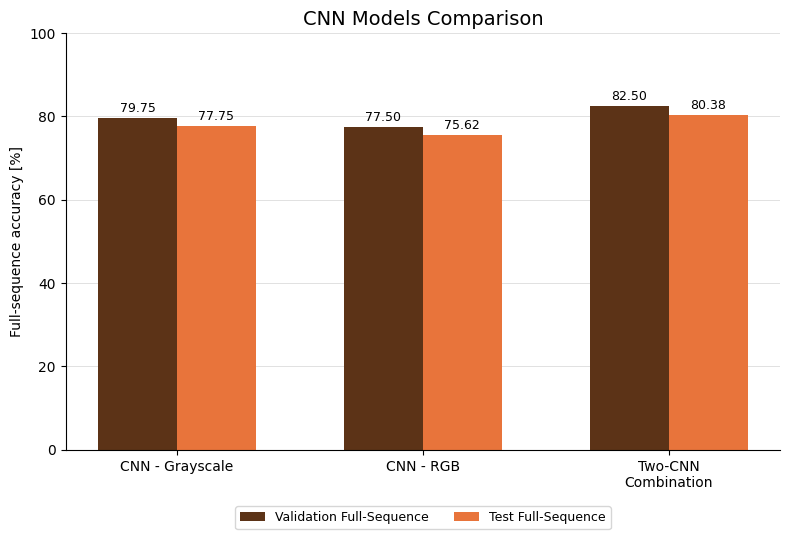

In [6]:
with open(resolve_path(CONFIG["paths"]["fusion_metrics"])) as f:
    fusion_metrics = json.load(f)

s = fusion_metrics["singles"]
c = fusion_metrics["combinations"]["cnn+cnn_rgb"]
group_labels = ["CNN - Grayscale", "CNN - RGB", "Two-CNN\nCombination"]
val_pct = [s["cnn"]["validation"]["full_sequence_accuracy"] * 100,
           s["cnn_rgb"]["validation"]["full_sequence_accuracy"] * 100,
           c["validation"]["full_sequence_accuracy"] * 100]
test_pct = [s["cnn"]["testing"]["full_sequence_accuracy"] * 100,
            s["cnn_rgb"]["testing"]["full_sequence_accuracy"] * 100,
            c["testing"]["full_sequence_accuracy"] * 100]

fig, ax = plt.subplots(figsize=(8, 5.5))
x = np.arange(len(group_labels)); width = 0.32

b1 = ax.bar(x - width/2, val_pct, width, label="Validation Full-Sequence", color="#5C3317")
b2 = ax.bar(x + width/2, test_pct, width, label="Test Full-Sequence", color="#E8743B")
ax.bar_label(b1, fmt="%.2f", fontsize=9, padding=2)
ax.bar_label(b2, fmt="%.2f", fontsize=9, padding=2)

ax.set_xticks(x); ax.set_xticklabels(group_labels)
ax.set_ylim(0, 100)
ax.set_ylabel("Full-sequence accuracy [%]")
ax.set_title("CNN Models Comparison", fontsize=14)
ax.set_axisbelow(True)
ax.grid(axis="y", color="lightgray", linewidth=0.7, alpha=0.7)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=9)
fig.tight_layout()
plt.show()

#### 4b. Digit-permutation synthesis (ablation step 6)

`DigitPermutationSynthesizer` (`src/augment.py`) builds a new training counter by filling each digit
slot with a digit patch from the same counter or, sometimes, a different one, giving readings that are
not in the dataset. It runs during training, so each epoch sees different synthetic readings. The cell
below draws a few examples.


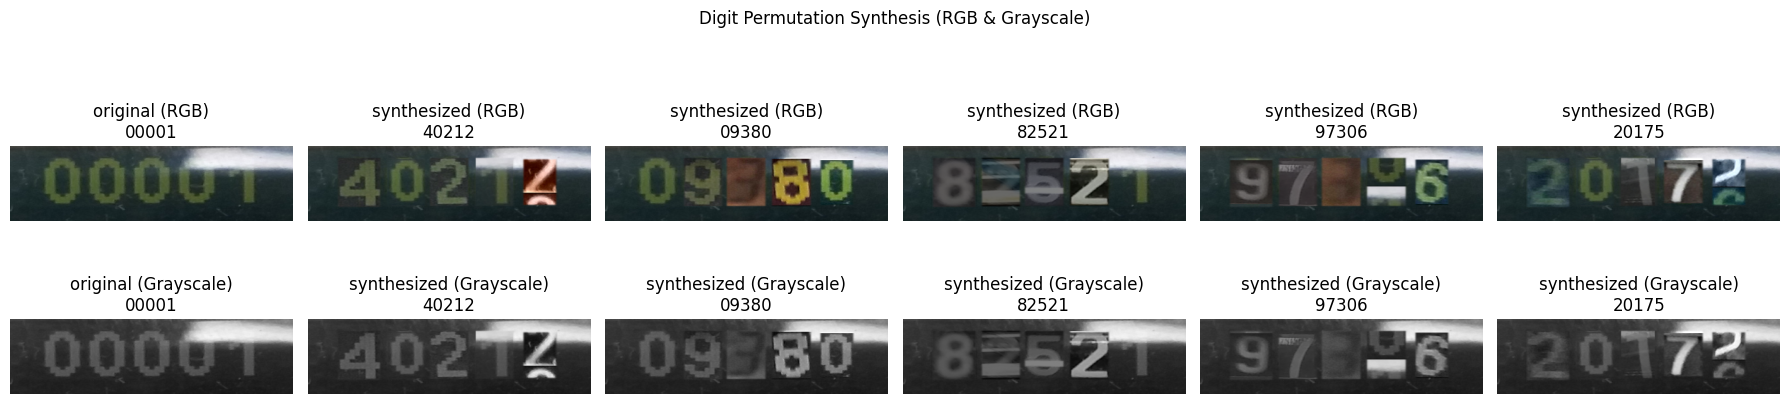

In [7]:
import cv2

from augment import DigitPermutationSynthesizer, crop_counter_with_margin

recog_dir = resolve_path(CONFIG["paths"]["recognition_dir"]) / "training"
with open(recog_dir / "geometry.json") as f:
    geometry = json.load(f)
with open(recog_dir / "labels.json") as f:
    labels = json.load(f)
basenames = sorted(labels.keys())

margin_images, geoms, readings = [], [], []
for b in basenames:
    img = cv2.imread(str(recog_dir / "counters_margin" / f"{b}.jpg"))
    margin_images.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    geoms.append(geometry[b])
    readings.append("".join(labels[b]))

aug_cfg = CONFIG["augmentation"]
synth = DigitPermutationSynthesizer(
    margin_images, geoms, readings,
    cross_counter_prob=aug_cfg["digit_permutation_cross_counter_prob"],
    transition_prob=aug_cfg["digit_transition_prob"],
    transition_split_range=aug_cfg["digit_transition_split_range"],
    same_polarity=aug_cfg.get("digit_permutation_same_polarity", True),
    feather_px=aug_cfg.get("digit_patch_feather_px", 3),
    contrast_gain_range=aug_cfg.get("digit_contrast_gain_range", (0.5, 2.0)),
)

counter_w, counter_h = CONFIG["image_sizes"]["counter_crop"]
margin_frac = aug_cfg["crop_margin_frac"]
base_idx = 0
n_variants = 5
to_gray = lambda crop: cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)  # same conversion as to_model_input in train_cnn.py

fig, axes = plt.subplots(2, n_variants + 1, figsize=(3 * (n_variants + 1), 4.6))
orig_crop = crop_counter_with_margin(margin_images[base_idx], geoms[base_idx]["counter_bbox"],
                                     (counter_w, counter_h), margin_frac)
axes[0, 0].imshow(orig_crop)
axes[0, 0].set_title(f"original (RGB)\n{readings[base_idx]}")
axes[0, 0].axis("off")
axes[1, 0].imshow(to_gray(orig_crop), cmap="gray", vmin=0, vmax=255)
axes[1, 0].set_title(f"original (Grayscale)\n{readings[base_idx]}")
axes[1, 0].axis("off")

for i in range(n_variants):
    synth_img, synth_reading = synth.synthesize(base_idx)
    crop = crop_counter_with_margin(synth_img, geoms[base_idx]["counter_bbox"],
                                    (counter_w, counter_h), margin_frac)
    axes[0, i + 1].imshow(crop)
    axes[0, i + 1].set_title(f"synthesized (RGB)\n{synth_reading}")
    axes[0, i + 1].axis("off")
    axes[1, i + 1].imshow(to_gray(crop), cmap="gray", vmin=0, vmax=255)
    axes[1, i + 1].set_title(f"synthesized (Grayscale)\n{synth_reading}")
    axes[1, i + 1].axis("off")

fig.suptitle("Digit Permutation Synthesis (RGB & Grayscale)", y=1.03)
fig.tight_layout()
plt.show()

#### 5. Training curves of the fine-tune stage (`results/cnn/cnn_history.json`)


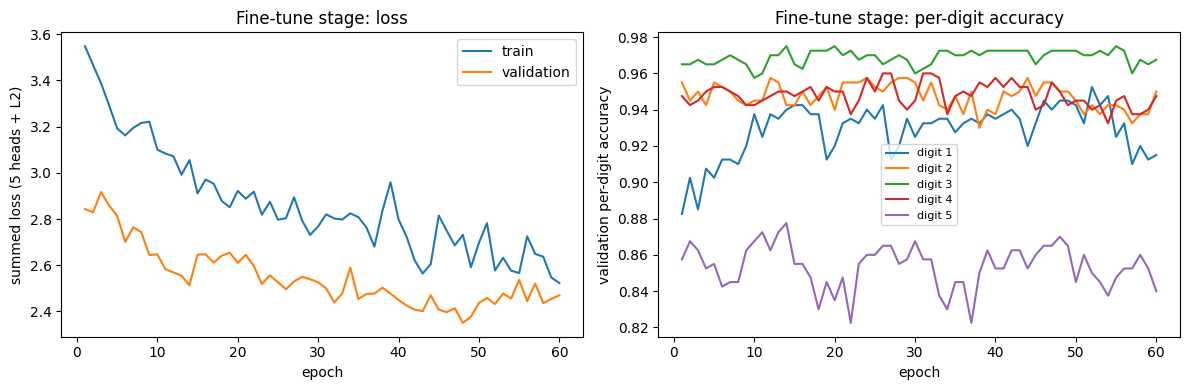

fine-tune: validation full-sequence 0.7800 -> 0.7975, kept = True


In [8]:
ep = range(1, len(history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep, history["loss"], label="train"); axes[0].plot(ep, history["val_loss"], label="validation")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("summed loss (5 heads + L2)"); axes[0].set_title("Fine-tune stage: loss"); axes[0].legend()
for i in range(1, 6):
    axes[1].plot(ep, history[f"val_digit_{i}_accuracy"], label=f"digit {i}")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation per-digit accuracy"); axes[1].set_title("Fine-tune stage: per-digit accuracy"); axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()
ft = metrics["finetune"]
print(f"fine-tune: validation full-sequence {ft['before_val_full_sequence_accuracy']:.4f} -> {ft['after_val_full_sequence_accuracy']:.4f}, kept = {ft['kept']}")

#### 6. Where the errors are (deployed model, saved probabilities)

In [9]:
rows = []
for split, key in [("validation", "cnn_val_probs"), ("testing", "cnn_test_probs")]:
    _, T, P = load_probs(CONFIG["paths"][key])
    ok = P.argmax(-1) == T
    wrong = ~ok.all(1)
    only_d5 = (ok.sum(1) == 4) & ~ok[:, 4]
    conf = P.max(-1).min(1)
    rows.append({"split": split, "images": len(T), "wrong readings": int(wrong.sum()),
                 "errors per position d1..d5": " / ".join(str(int(x)) for x in (~ok).sum(0)),
                 "wrong only at d5": int(only_d5.sum()), "if d5 were perfect": float(ok[:, :4].all(1).mean()),
                 "product of per-digit acc.": float(np.prod(ok.mean(0))), "measured full-seq": float(ok.all(1).mean()),
                 "median conf. correct": float(np.median(conf[~wrong])), "median conf. wrong": float(np.median(conf[wrong]))})
print(pd.DataFrame(rows).T.to_string())

                                                 0                       1
split                                   validation                 testing
images                                         400                     800
wrong readings                                  81                     178
errors per position d1..d5  22 / 20 / 11 / 20 / 52  47 / 39 / 37 / 35 / 97
wrong only at d5                                30                      65
if d5 were perfect                          0.8725                 0.85875
product of per-digit acc.                 0.721586                0.717581
measured full-seq                           0.7975                  0.7775
median conf. correct                      0.836773                0.853925
median conf. wrong                        0.396064                 0.44583


**Observation:** Digit 5 accounts for about 40% of the remaining errors: the last drum
turns fastest and is most often photographed between two numbers. Measured full-sequence
accuracy is above the product of the per-digit accuracies, so errors are correlated across
positions (a hard photo breaks several digits at once) - which is why fusing with a model
that fails on different photos helps (Phase 6). Wrong readings have much lower confidence
than correct ones, which the decision layer (Phase 8) relies on.
